<a href="https://colab.research.google.com/github/gaya123-git/Flowers_Image_Recognition_Project/blob/main/Flowers_Image_Recognition_Project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install -q importlib_resources tensorflow-datasets
!rm -rf /root/tensorflow_datasets/tf_flowers
!pip install -q tensorflow-datasets
import tensorflow as tf
import tensorflow_datasets as tfds
import matplotlib.pyplot as plt
print(tf.__version__)

2.21.0


In [2]:
IMG = 224
(train_ds, val_ds), info = tfds.load(
    "tf_flowers",
    split=["train[:80%]", "train[80%:]"],
    as_supervised=True,
    with_info=True,
)
class_names = info.features["label"].names
num_classes = len(class_names)
print(class_names)

Dl Completed...: 0 url [00:00, ? url/s]

Dl Size...: 0 MiB [00:00, ? MiB/s]

Generating splits...:   0%|          | 0/1 [00:00<?, ? splits/s]

Generating train examples...: 0 examples [00:00, ? examples/s]

Shuffling /root/tensorflow_datasets/tf_flowers/incomplete.CXXWHX_3.0.1/tf_flowers-train.tfrecord-[0-9][0-9][0-…

Dataset tf_flowers downloaded and prepared to /root/tensorflow_datasets/tf_flowers/3.0.1. Subsequent calls will reuse this data.
['dandelion', 'daisy', 'tulips', 'sunflowers', 'roses']


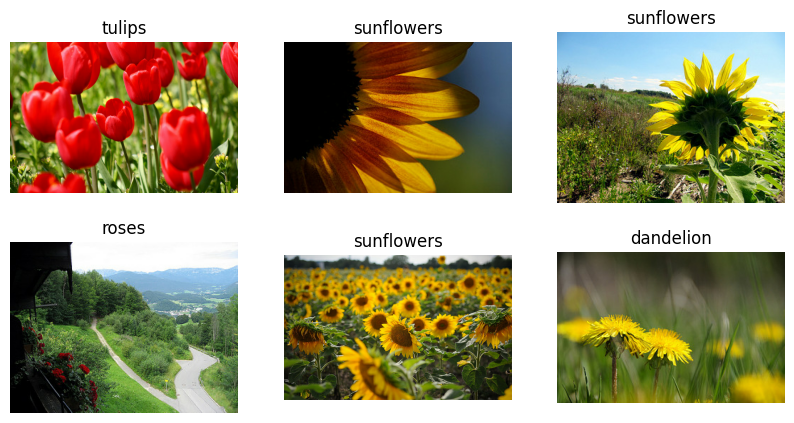

In [3]:
plt.figure(figsize=(10, 5))
for i, (img, label) in enumerate(train_ds.take(6)):
    plt.subplot(2, 3, i + 1)
    plt.imshow(img)
    plt.title(class_names[label])
    plt.axis("off")
plt.show()

In [4]:
def prep(image, label):
    image = tf.image.resize(image, (IMG, IMG))
    return image, label

train_batches = train_ds.map(prep).shuffle(1000).batch(32).prefetch(tf.data.AUTOTUNE)
val_batches = val_ds.map(prep).batch(32).prefetch(tf.data.AUTOTUNE)

In [5]:
base = tf.keras.applications.MobileNetV3Small(
    input_shape=(IMG, IMG, 3), include_top=False, weights="imagenet"
)
base.trainable = False

model = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal"),
    base,
    tf.keras.layers.GlobalAveragePooling2D(),
    tf.keras.layers.Dropout(0.2),
    tf.keras.layers.Dense(num_classes),
])

model.compile(
    optimizer="adam",
    loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),
    metrics=["accuracy"],
)

4334752/4334752 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


In [6]:
history = model.fit(train_batches, validation_data=val_batches, epochs=5)

Epoch 1/5
92/92 ━━━━━━━━━━━━━━━━━━━━ 56s 332ms/step - accuracy: 0.6352 - loss: 0.9589 - val_accuracy: 0.8188 - val_loss: 0.5821
Epoch 2/5
92/92 ━━━━━━━━━━━━━━━━━━━━ 4s 33ms/step - accuracy: 0.8038 - loss: 0.5535 - val_accuracy: 0.8597 - val_loss: 0.4480
Epoch 3/5
92/92 ━━━━━━━━━━━━━━━━━━━━ 4s 33ms/step - accuracy: 0.8518 - loss: 0.4360 - val_accuracy: 0.8856 - val_loss: 0.3939
Epoch 4/5
92/92 ━━━━━━━━━━━━━━━━━━━━ 5s 33ms/step - accuracy: 0.8644 - loss: 0.3928 - val_accuracy: 0.8856 - val_loss: 0.3646
Epoch 5/5
92/92 ━━━━━━━━━━━━━━━━━━━━ 4s 33ms/step - accuracy: 0.8808 - loss: 0.3684 - val_accuracy: 0.8896 - val_loss: 0.3461


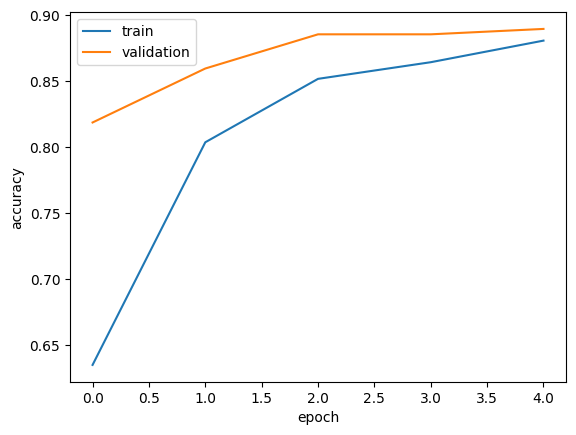

In [7]:
plt.plot(history.history["accuracy"], label="train")
plt.plot(history.history["val_accuracy"], label="validation")
plt.xlabel("epoch"); plt.ylabel("accuracy"); plt.legend(); plt.show()

1/1 ━━━━━━━━━━━━━━━━━━━━ 7s 7s/step


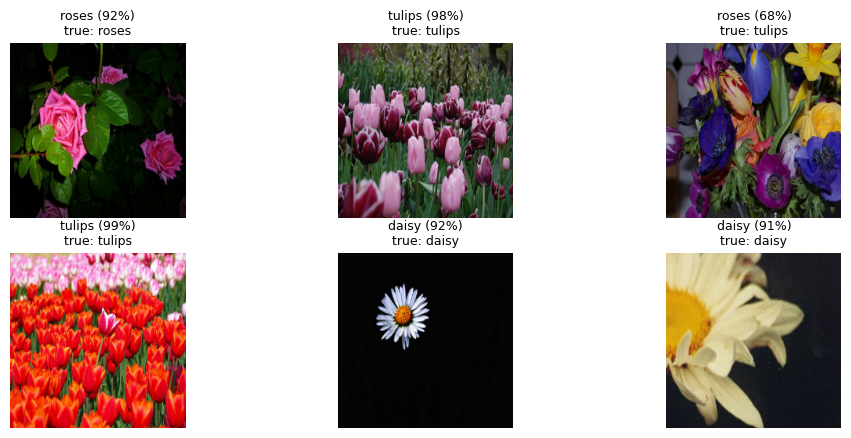

In [8]:
for imgs, labels in val_batches.take(1):
    probs = tf.nn.softmax(model.predict(imgs[:6]))
    plt.figure(figsize=(12, 5))
    for i in range(6):
        plt.subplot(2, 3, i + 1)
        plt.imshow(imgs[i].numpy().astype("uint8"))
        guess = class_names[probs[i].numpy().argmax()]
        conf = probs[i].numpy().max()
        truth = class_names[labels[i]]
        plt.title(f"{guess} ({conf:.0%})\ntrue: {truth}", fontsize=9)
        plt.axis("off")
    plt.show()